<h1>Introduction to Byzantine Fault Tolerance in Federated Learning</h1>

<h2>Introduction</h2>

This notebook explores <b>Byzantine fault tolerance in Federated Learning (FL)</b>: training a single model across many parties that never share their data, when some of those parties may be faulty or malicious.

Before getting to Byzantine robustness, the notebook first goes over the <b>key theoretical aspects of federated learning</b>: the federated objective, the FedAvg algorithm, and why clients with different data (non-IID clients) make the optimization harder. These foundations are what explain, later on, why a malicious client can be hard to tell apart from an honest one.

<b>The scenario</b>

The coast guards and maritime agencies of several countries want a shared model that detects ships in satellite imagery. Each agency already has its own labeled image archive, but the archives <b>cannot be pooled</b>:
- the imagery may be security-sensitive or classified
- commercial imagery is often licensed to one organization and cannot be redistributed
- national data-sovereignty rules may forbid moving the data abroad

So instead of sending data to a central server, each agency trains on its own archive and only sends <b>model updates</b> to a coordinating server, which combines them into one global model. This is an example of <i>Federated Learning</i>.

<b>How is Byzantine robustness relevant here?</b>

The server never sees the data, so it cannot check whether an update is honest. A compromised station, a buggy pipeline or a deliberately malicious participant can send <i>anything</i>. A ship detector that has quietly learned to miss ships is exactly what a vessel trying to stay "dark" (e.g. after switching off its AIS transponder) would want.

<b>Byzantine clients in short</b>

The term comes from the <i>Byzantine Generals Problem</i> ([Lamport, Shostak, Pease, 1982](https://doi.org/10.1145/357172.357176)): reaching agreement when some participants may lie. In FL:
- a <b>Byzantine client</b> is one that can deviate from the protocol in <u>any</u> way: it can send arbitrary updates, not just noisy ones
- the worst case is assumed: Byzantine clients may know the aggregation rule, see the honest updates, and coordinate with each other
- out of $N$ clients, up to $f$ are assumed to be Byzantine, and the server does not know which ones
- plain averaging (FedAvg) has no protection: a single Byzantine client can move the global model arbitrarily far
- <b>Byzantine-robust aggregation rules</b> (e.g. Krum, [Blanchard et al., 2017](https://arxiv.org/abs/1703.02757)) replace the average with a rule that limits how much any small group of clients can influence the result, as long as $f$ stays below some fraction of $N$

The full threat model, a concrete attack and a defense are developed later, after the federated learning foundations are in place.

<b>Note 1:</b> This is a deliberately <b>simplified</b> example: a small public dataset, a small CNN, and a federation of 10 clients simulated on a single machine. It is not a model of a real maritime surveillance system. The goal is to demonstrate the key concepts on a fun use case that is close to real scenarios.

<b>Note 2:</b> This is the sister notebook of [<i>Adversarially Robust CNN for CIFAR-10</i>](https://github.com/nefsxt/adversarially-robust-cnn-cifar10). Basics such as CNN layers, DataLoaders and the standard training loop are explained there and only briefly recapped here.

<h2>Outline</h2>

- Imports and Configuration
- Dataset
- Federated Learning
    - Centralized vs Federated Training
    - Federated Averaging (FedAvg)
    - IID vs Non-IID Clients
    - An Optimization Perspective on IID vs Non-IID (and Client Drift)
- The No-Attack Case: FedAvg on IID and Non-IID Clients
- The Byzantine Threat Model <i>(coming next)</i>
- Attacks and Defenses <i>(coming next)</i>
- Resources

<h2>Imports and Configuration</h2>

In [1]:
# Core PyTorch
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.nn.utils import parameters_to_vector, vector_to_parameters # model <-> flat vector

# Standard libraries
import json
import random
import shutil
import time
from dataclasses import dataclass, asdict, replace
from pathlib import Path

# Others
import matplotlib.pyplot as plt
import numpy as np

# Device config - run on GPU if available
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using device:", device)
if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Using device: cuda
GPU: NVIDIA GeForce RTX 5060 Laptop GPU


<h3>Configuration</h3>

All the settings of the notebook live in a single <b>dataclass</b>:
- one place to read and change every hyperparameter
- `replace(cfg, local_epochs=5)` creates a modified copy for an experiment without touching the original
- `asdict(cfg)` turns it into a dictionary, so the exact settings can be saved together with the results

In [2]:
@dataclass
class Config:
    # --- Data ---
    data_dir: str = "./data"
    test_fraction: float = 0.2      # size of the held-out central test set
    split_seed: int = 11            # fixed -> same test set for every experiment

    # --- Federation ---
    num_clients: int = 10           # N
    rounds: int = 30                # T, communication rounds
    local_epochs: int = 2           # E, passes over the local data per round
    dirichlet_alpha: float = 0.5    # non-IID strength (smaller = more skewed, larger = closer to IID )
    min_client_size: int = 32       # re-draw the partition if a client gets fewer samples

    # --- Local optimization ---
    batch_size: int = 32            # B
    lr: float = 0.01                # eta
    momentum: float = 0.9

    # --- Experiments ---
    seeds: tuple = (0, 1, 2)        # every experiment is repeated over these seeds
    results_dir: str = "./results"
    rerun: bool = False             # False -> load cached results if they exist

cfg = Config()
cfg

Config(data_dir='./data', test_fraction=0.2, split_seed=11, num_clients=10, rounds=30, local_epochs=2, dirichlet_alpha=0.5, min_client_size=32, batch_size=32, lr=0.01, momentum=0.9, seeds=(0, 1, 2), results_dir='./results', rerun=False)

<h3>Reproducibility</h3>

Python, NumPy and PyTorch each have their <b>own random number generator</b>, so all of them have to be seeded.
- `torch.manual_seed` also seeds the CUDA generators
- cuDNN picks the fastest convolution algorithm at runtime, and some of those are non-deterministic. Turning `benchmark` off and `deterministic` on trades a little speed for repeatable runs
- even then, results can differ slightly across GPUs and library versions, which is one more reason to report every experiment over several seeds

In [3]:
def set_seed(seed):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)          # seeds CPU and all CUDA devices
    torch.cuda.manual_seed_all(seed)

torch.backends.cudnn.deterministic = True # forces cuDNN (NVIDIA's deep learning library) to only use deterministic algorithms
torch.backends.cudnn.benchmark = False # disables the cuDNN auto-tune

set_seed(cfg.split_seed)

A small fixed color set is used for every plot, so the same thing always has the same color (e.g. ships are always orange, IID results always blue). The toy optimization example uses two extra colors of its own, violet and green, for its two clients.

In [4]:
COLORS = {
    "no_ship":     "#2a78d6",   # blue
    "ship":        "#eb6834",   # orange
    "iid":         "#2a78d6",   # blue
    "non_iid":     "#eb6834",   # orange
    "centralized": "#52514e",   # gray (reference)
    "accent":      "#1baf7a",   # aqua
    # used only in the toy optimization example, for its two clients
    "client_1":    "#6250d6",   # violet
    "client_2":    "#008300",   # green
}

<h2>Dataset</h2>

The dataset that is utilized is <b>Ships in Satellite Imagery</b> ([Kaggle: rhammell/ships-in-satellite-imagery](https://www.kaggle.com/datasets/rhammell/ships-in-satellite-imagery)).
- image chips extracted from [Planet](https://www.planet.com/) satellite imagery over the San Francisco Bay and San Pedro Bay areas of California
- 4000 RGB images of $80 \times 80$ pixels, at roughly 3 m per pixel
- 2 classes: <b>ship</b> (1000 images) and <b>no-ship</b> (3000 images)
- licensed under CC BY-SA 4.0, so any reuse must credit the source

The <b>no-ship</b> class is deliberately hard. According to the dataset description it is split into thirds:
- random land cover (water, vegetation, bare earth, buildings) without any part of a ship
- <b>partial ships</b>: chips that contain only a portion of a ship
- chips that earlier machine learning models had <b>mislabeled</b> as ships, typically because of bright pixels or strong linear features

<b>File format</b>

The dataset comes as a folder of PNGs and as a single `shipsnet.json`, which is what we use. It contains:
- `data`: one list of 19200 integers per image. The first 6400 are the red channel, the next 6400 green and the last 6400 blue, each stored row by row
- `labels`: <b>1 = ship</b> and <b>0 = no-ship</b>
- `scene_ids` and `locations`: the source scene and the coordinates of each chip

Because the channels are stored one after the other, a plain `reshape(-1, 3, 80, 80)` already gives the $C \times H \times W$ layout PyTorch expects. No transpose is needed (unlike the PIL images of the sister notebook, which are $H \times W \times C$).

<b>Getting the data</b>
- <u>Option A (automatic):</u> the cell below downloads the dataset with `kagglehub`. Public datasets can usually be downloaded without an account; if you get an authentication error, create an API token in your Kaggle account settings and either place `kaggle.json` in `~/.kaggle/` or set the `KAGGLE_USERNAME` and `KAGGLE_KEY` environment variables
- <u>Option B (manual):</u> download the dataset from the Kaggle page and place `shipsnet.json` in `./data/`

In [5]:
def get_shipsnet_json(data_dir):
    """Returns the path to shipsnet.json, downloading it with kagglehub if it is missing."""
    data_dir = Path(data_dir)
    json_path = data_dir / "shipsnet.json"
    if json_path.exists():
        return json_path

    try:
        import kagglehub
        download_dir = Path(kagglehub.dataset_download("rhammell/ships-in-satellite-imagery"))
        found = next(download_dir.rglob("shipsnet.json"))   # search the downloaded folder
        data_dir.mkdir(parents=True, exist_ok=True)
        shutil.copy(found, json_path)
        return json_path
    except Exception as e:
        raise FileNotFoundError(
            f"Could not download the dataset automatically ({e}).\n"
            f"Download it from https://www.kaggle.com/datasets/rhammell/ships-in-satellite-imagery "
            f"and place shipsnet.json in {data_dir.resolve()}"
        )

Parsing a ~300 MB JSON file of Python integers is slow, so after the first load the arrays are cached as a compressed `.npz` file. Every later run loads that instead.

In [6]:
def load_shipsnet(data_dir):
    cache = Path(data_dir) / "shipsnet.npz"
    if cache.exists():
        d = np.load(cache)
        return d["X"], d["y"], d["scene_ids"]

    with open(get_shipsnet_json(data_dir)) as f:
        raw = json.load(f)

    X = np.array(raw["data"], dtype=np.uint8).reshape(-1, 3, 80, 80)   # (N, C, H, W)
    y = np.array(raw["labels"], dtype=np.int64)
    scene_ids = np.array(raw["scene_ids"])

    np.savez_compressed(cache, X=X, y=y, scene_ids=scene_ids)
    return X, y, scene_ids


X_all, y_all, scene_ids = load_shipsnet(cfg.data_dir)
print("Images:", X_all.shape, X_all.dtype)
print("Labels:", y_all.shape)
print("Source scenes:", len(np.unique(scene_ids)))

Images: (4000, 3, 80, 80) uint8
Labels: (4000,)
Source scenes: 434


The expected shapes are
- images = (4000, 3, 80, 80): 4000 images, 3 channels (RGB), $80 \times 80$ pixels
- labels = (4000,): a single label for each image

<h3>Class Imbalance</h3>

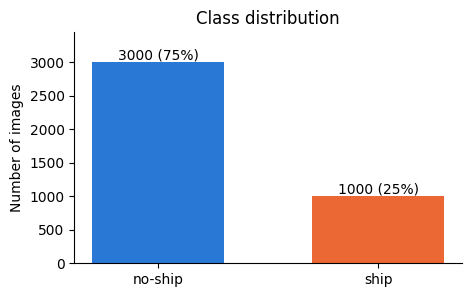

In [7]:
counts = np.bincount(y_all)

fig, ax = plt.subplots(figsize=(5, 3))
ax.bar(["no-ship", "ship"], counts, color=[COLORS["no_ship"], COLORS["ship"]], width=0.6)
for i, c in enumerate(counts):
    ax.text(i, c + 50, f"{c} ({c / counts.sum():.0%})", ha="center")
ax.set_ylabel("Number of images")
ax.set_title("Class distribution")
ax.set_ylim(0, counts.max() * 1.15)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

The classes are imbalanced 3:1. This has an important consequence: <b>a model that never predicts "ship" still reaches 75% accuracy</b>.

For a ship detector, that model is useless: it is completely blind. Accuracy alone can therefore hide exactly the failure we care about, so later on we will also track metrics that focus on the ship class.

<h3>Visualizing the Chips</h3>

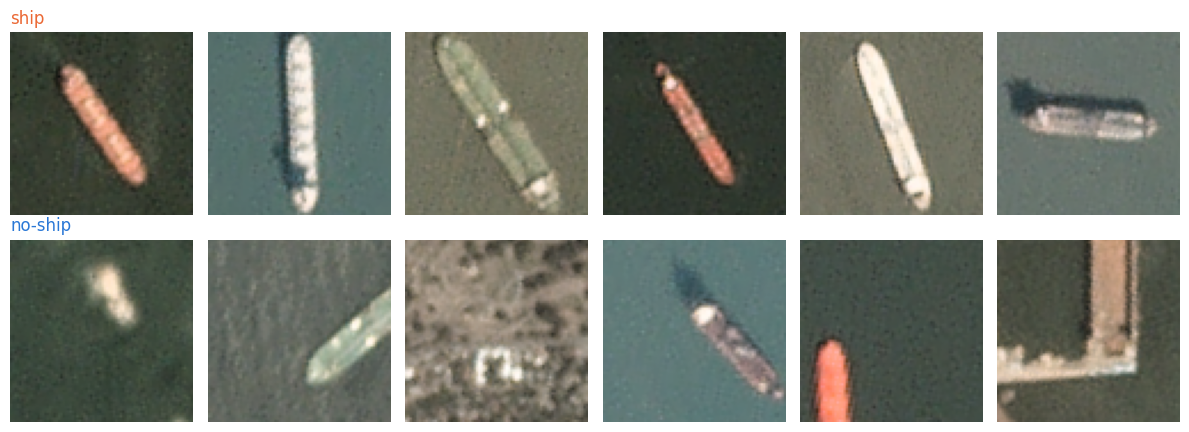

In [8]:
def show_chips(X, y, n_per_class=6, seed=0):
    rng = np.random.default_rng(seed)
    fig, axes = plt.subplots(2, n_per_class, figsize=(2 * n_per_class, 4.4))
    for row, (label, name) in enumerate([(1, "ship"), (0, "no-ship")]):
        idx = rng.choice(np.where(y == label)[0], n_per_class, replace=False)
        for col, i in enumerate(idx):
            axes[row, col].imshow(X[i].transpose(1, 2, 0))   # C x H x W -> H x W x C for matplotlib
            axes[row, col].axis("off")
        axes[row, 0].set_title(name, loc="left", color=COLORS["ship" if label else "no_ship"])
    plt.tight_layout()
    plt.show()

show_chips(X_all, y_all)

The ship chips have the ship centered in the frame. Several no-ship chips contain <b>partial ships</b>, piers or bright linear structures; these "hard negatives" are what keeps the task from being trivial.

<h3>Train / Test Split</h3>

As in the sister notebook, we only have a finite sample $\hat{D}=\{(x_i,y_i)\}$ of the unknown data distribution $D$, which we split into $\hat{D}_{train}$ and $\hat{D}_{test}$.
- the split is <b>stratified</b>: both sets keep the 75/25 class ratio
- the split seed is fixed, so <u>every experiment is evaluated on the exact same test images</u>
- only $\hat{D}_{train}$ is distributed among the clients. $\hat{D}_{test}$ stays with the server and no client ever trains on it

<b>Notes:</b>
- A central test set held by the server is a <b>simulation convenience</b>. In a real deployment the server usually has no data at all and evaluation is itself a federated problem.
- Chips cut from the same source scene can end up in both sets, which makes the absolute scores somewhat optimistic. Since we only compare methods against each other on the same split, this is acceptable here.

In [9]:
def stratified_split(y, test_fraction, seed):
    rng = np.random.default_rng(seed)
    test_idx = [] # store test set indexes 
    # for each unique class label 
    for c in np.unique(y):
        idx_c = rng.permutation(np.where(y == c)[0])                      # find all corresponding index positions and shuffle
        test_idx.append(idx_c[: int(round(test_fraction * len(idx_c)))])  # save the amount of necessary shuffled points for test set
    test_idx = np.sort(np.concatenate(test_idx))                          # combine the indexes chosen from the different classes in one array 
    train_idx = np.setdiff1d(np.arange(len(y)), test_idx)                 # create the train set by removing the test set indexes
    return train_idx, test_idx


train_idx, test_idx = stratified_split(y_all, cfg.test_fraction, cfg.split_seed)
y_train_np = y_all[train_idx]   # numpy copy of the train labels, used for partitioning
print(f"Train: {len(train_idx)} images ({y_train_np.mean():.0%} ships)")
print(f"Test:  {len(test_idx)} images ({y_all[test_idx].mean():.0%} ships)")

Train: 3200 images (25% ships)
Test:  800 images (25% ships)


<b>PyTorch note:</b> the whole dataset is only ~300 MB as `float32`, so it fits on the GPU at once. That means:
- no `DataLoader` is needed. Batches are formed by indexing GPU tensors directly, which is much faster than loading from the CPU every step
- the images are moved to the GPU as `uint8` and only converted to `float` there: 4$\times$ less data to transfer
- `.div_(255)` scales the pixels from $[0,255]$ to $[0,1]$ in place (the trailing `_` marks an in-place operation)

In [10]:
X_train = torch.from_numpy(X_all[train_idx]).to(device).float().div_(255)
y_train = torch.from_numpy(y_all[train_idx]).to(device).float()   # float labels for the BCE loss
X_test  = torch.from_numpy(X_all[test_idx]).to(device).float().div_(255)
y_test  = torch.from_numpy(y_all[test_idx]).to(device).float()

print(X_train.shape, y_train.shape, X_train.device)

torch.Size([3200, 3, 80, 80]) torch.Size([3200]) cuda:0


<h2>Federated Learning</h2>

<b>What changes when the data cannot be pooled?</b>

<h3>Centralized vs Federated Training</h3>

In the <b>centralized</b> setting, all the data sits in one place and we minimize the empirical risk over the pooled dataset of $n$ samples:

$$\hat{R}(\theta) = \frac{1}{n}\sum_{(x,y)\in\hat{D}_{train}} l(h_{\theta}(x),y)$$

In the <b>federated</b> setting, the data is split across $N$ clients.
- client $i$ holds a local dataset $\hat{D}_i$ of $n_i$ samples, with $n=\sum_i n_i$
- each client has its own <b>local empirical risk</b>, written $f_i$ for brevity: $f_i(\theta) = \hat{R}_i(\theta) = \frac{1}{n_i}\sum_{(x,y)\in\hat{D}_i} l(h_{\theta}(x),y)$
- the goal is to minimize the weighted sum of the local risks:

$$\min_{\theta} F(\theta) = \sum_{i=1}^{N} p_i f_i(\theta), \qquad p_i = \frac{n_i}{n}$$

Expanding the weights shows that the two objectives are <b>identical</b>:

$$F(\theta) = \sum_{i} \frac{n_i}{n} \cdot \frac{1}{n_i}\sum_{(x,y)\in\hat{D}_i} l(h_{\theta}(x),y) = \frac{1}{n}\sum_{(x,y)\in\hat{D}_{train}} l(h_{\theta}(x),y) = \hat{R}(\theta)$$

<u><b>The objective does not change. What changes is who can compute what.</b></u> The server can neither evaluate $F$ nor its gradient, because only client $i$ can compute the terms that involve $\hat{D}_i$.

| Feature | Centralized Training | Federated Training |
| -------- | ------- | ------- |
| Data location | One server | Stays on each client |
| Who computes gradients | The server, on any batch it likes | Each client, only on its own data |
| What travels over the network | Nothing (or raw data, once) | Model parameters / updates, every round |
| Batches | Shuffled from all the data, so each batch is a sample of the same distribution | Fixed per client, possibly from very different distributions |
| Main bottleneck | Compute | Communication rounds |
| Trust | The server sees everything | The server sees updates only, and cannot verify them |

The last row is a core reason why it is important to explore the topic of Byzantine fault tolerance: the server must <b>trust</b> updates that it can't verify.

<h3>Federated Averaging (FedAvg)</h3>

<b>FedAvg</b> ([McMahan et al., 2017](https://arxiv.org/abs/1602.05629)) is the standard FL algorithm. 
<br></br>
<br>In each communication round $t$:</br>
1. The server sends the current global model $\theta_t$ to every client
2. Each client runs $K$ steps of (stochastic) gradient descent on its own $f_i$, starting from $\theta_t$, and ends at a local model $\theta_{t,i}$
3. The server averages the local models, weighted by data size: $\theta_{t+1} = \sum_i p_i\,\theta_{t,i}$

The same step can be written in terms of <b>updates</b> $\Delta_i = \theta_{t,i} - \theta_t$:

$$\theta_{t+1} = \theta_t + \sum_i p_i\,\Delta_i$$

- this is what clients actually send, and how it is implemented here
- it is also what a <b>Byzantine client controls</b>: it can send any $\Delta_i$ it wants. Since the average is linear, a single client can shift $\theta_{t+1}$ arbitrarily far by sending a large enough update. We will come back to this in the threat model section.

<b>Why $K$ local steps and not just one?</b>
- With $K = 1$, every client computes one gradient at the same point $\theta_t$ and the server averages them: $\theta_{t+1} = \theta_t - \eta\sum_i p_i \nabla f_i(\theta_t) = \theta_t - \eta\nabla F(\theta_t)$. This is exactly gradient descent on $F$ (called FedSGD), because the gradient of a weighted sum is the weighted sum of gradients.
- But every step then costs a full communication round, which is the expensive part of FL.
- With $K > 1$, clients make more progress per round and far fewer rounds are needed. The price is that clients spend those steps descending their <u>own</u> $f_i$ instead of $F$. The optimization perspective below shows exactly what that costs.
- In practice $K$ is set through the number of local epochs $E$: client $i$ takes $K_i = E \cdot \lceil n_i / B \rceil$ steps, so clients with more data take more steps.

<h3>IID vs Non-IID Clients</h3>

In centralized training, shuffling guarantees that every batch looks like the full dataset. In FL the data is split by <b>who collected it</b>, and nothing guarantees that.
<br></br>
In the simplified maritime scenario examined in this notebook, some examples of how data collection could result in different datasets are the following: 
- a station covering a busy harbour sees mostly ships
- a station watching open ocean sees almost none
- stations can also differ in sensors, sea states and lighting

<b>IID clients:</b> every local dataset $\hat{D}_i$ is a sample of the same distribution (independent and identically distributed). Each client is a small copy of the full dataset.

<b>Non-IID clients:</b> the local distributions differ. The common types are ([Kairouz et al., 2021](https://arxiv.org/abs/1912.04977); [Hsieh et al., 2020](https://arxiv.org/abs/1910.00189)):
- <b>label skew</b>: the class proportions $P_i(y)$ differ (the harbour vs open-ocean example)
- <b>feature skew</b>: the same class looks different, $P_i(x \mid y)$ differs (different sensors or sea states)
- <b>quantity skew</b>: the clients hold very different amounts of data $n_i$

For the purposes of this notebook, the skew simulated is <b>label skew</b>, which also produces <b>quantity skew</b> as a side effect.

<b>How the partitions are generated</b>
- <u>IID:</u> shuffle the training set and split it into $N$ equal parts. Each client gets ~75% no-ship and ~25% ship
- <u>Non-IID (Dirichlet):</u> for each class $c$, draw a vector of proportions $q_c \sim \mathrm{Dir}(\alpha \mathbf{1}_N)$ and give client $i$ a fraction $q_{c,i}$ of the class-$c$ images ([Hsu et al., 2019](https://arxiv.org/abs/1909.06335))
    - $\alpha$ controls how uneven the proportions are
    - $\alpha \rightarrow \infty$: the proportions become uniform and the partition approaches IID
    - $\alpha \rightarrow 0$: each class is concentrated on very few clients

In [11]:
def iid_partition(num_samples, num_clients, rng):
    """Shuffle and split into equal parts. Returns a list of index arrays, one per client."""
    return np.array_split(rng.permutation(num_samples), num_clients)


def dirichlet_partition(labels, num_clients, alpha, rng, min_size=1, max_tries=1000):
    """Label-skewed split: class c is divided among clients with proportions q_c ~ Dir(alpha)."""
    # max retries necessary because the sampling process is random -> clients can end up empty or with less than desired samples
    for _ in range(max_tries):
        client_idx = [[] for _ in range(num_clients)] # each client has its own list of indexes for the data partitions it will receive
        # for each unique class label 
        for c in np.unique(labels):
            idx_c = rng.permutation(np.where(labels == c)[0])          # get a random permutation of indexes of all data points of that class
            q_c = rng.dirichlet(alpha * np.ones(num_clients))          # generate proportions vector via Dirichlet distribution (they sum to 1)
            cuts = (np.cumsum(q_c)[:-1] * len(idx_c)).astype(int)      # calculate the data sample cut indexes for each (drop last one so split doesn't try to create an extra subset)
            for i, part in enumerate(np.split(idx_c, cuts)):
                client_idx[i].extend(part.tolist()) # append data partition indexes of this class to client i
        # re-draw if a client ended up (almost) empty 
        if min(len(ci) for ci in client_idx) >= min_size:
            return [rng.permutation(ci) for ci in client_idx]
    raise RuntimeError("Could not satisfy min_size; lower it or increase alpha.") 

<b>Note:</b> with a small $\alpha$, some clients can receive almost nothing. A client with fewer images than one batch is not useful for training, so the partition is re-drawn until every client has at least `min_client_size` images.

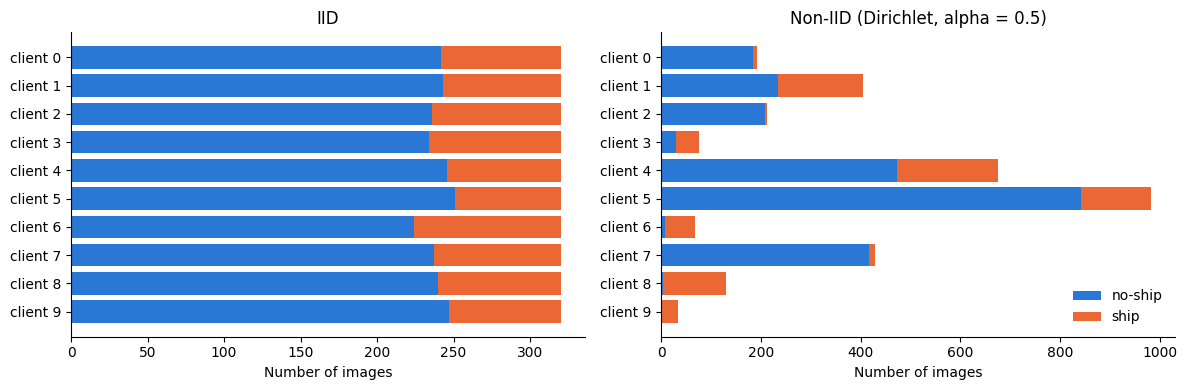

In [12]:
def plot_partition(partition, labels, ax, title):
    clients = np.arange(len(partition))
    ships = np.array([labels[p].sum() for p in partition])
    no_ships = np.array([len(p) for p in partition]) - ships
    ax.barh(clients, no_ships, color=COLORS["no_ship"], label="no-ship")
    ax.barh(clients, ships, left=no_ships, color=COLORS["ship"], label="ship")
    ax.set_yticks(clients, [f"client {i}" for i in clients])
    ax.invert_yaxis()
    ax.set_xlabel("Number of images")
    ax.set_title(title)
    ax.spines[["top", "right"]].set_visible(False)


rng = np.random.default_rng(0)
iid_parts = iid_partition(len(y_train_np), cfg.num_clients, rng)
non_iid_parts = dirichlet_partition(y_train_np, cfg.num_clients, cfg.dirichlet_alpha, rng, cfg.min_client_size)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
plot_partition(iid_parts, y_train_np, axes[0], "IID")
plot_partition(non_iid_parts, y_train_np, axes[1], f"Non-IID (Dirichlet, alpha = {cfg.dirichlet_alpha})")
axes[1].legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

In the IID split every client has the same size and the same 3:1 class ratio. In the non-IID split some clients see mostly ships, others almost none, and the client sizes differ widely.

To get a feel for $\alpha$, the same split for several values:

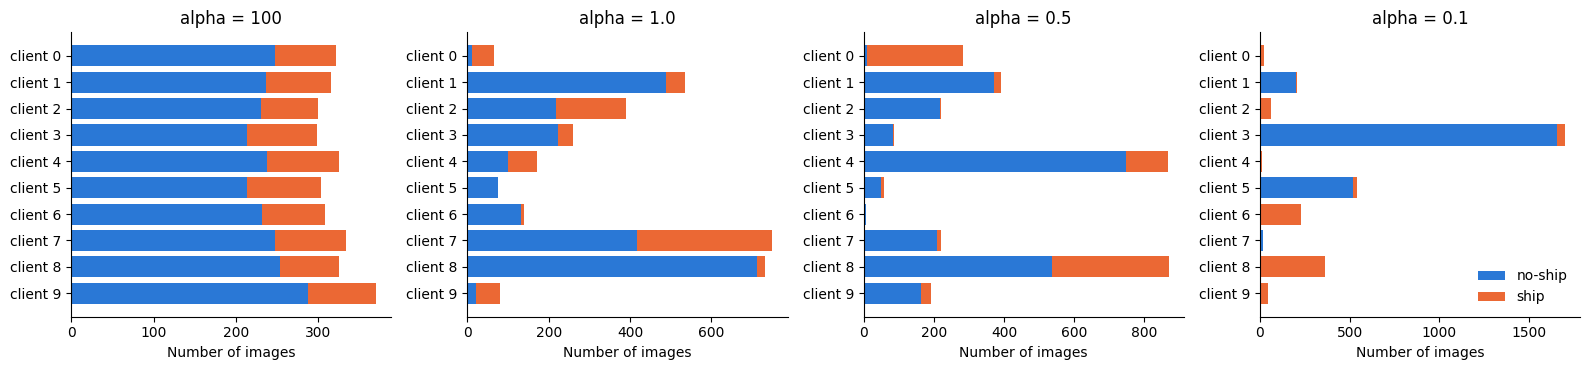

In [13]:
alphas = [100, 1.0, 0.5, 0.1]
fig, axes = plt.subplots(1, len(alphas), figsize=(16, 3.8))
for ax, a in zip(axes, alphas):
    parts = dirichlet_partition(y_train_np, cfg.num_clients, a, np.random.default_rng(0), min_size=1)
    plot_partition(parts, y_train_np, ax, f"alpha = {a}")
axes[-1].legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

With $\alpha = 100$ the split is practically IID. However, as $\alpha$ shrinks, what is observable is that both the class mix and the client sizes become more uneven. With $\alpha = 0.1$ most clients hold almost only one class.

<h3>An Optimization Perspective on IID vs Non-IID (and Client Drift)</h3>

<b>If the federated objective $F$ is identical to the centralized one, why should non-IID data hurt FedAvg at all?</b>

The objective is the same, but the <u>algorithm</u> is not plain gradient descent on it. To see where FedAvg actually ends up, it helps to look at the problem as an optimization problem.

<u><b>1. Setup</b></u>
- $N$ clients share one parameter space, each with its own loss $f_i(\theta)$
- the goal is $\min_{\theta} F(\theta) = \sum_i p_i f_i(\theta)$
- $\theta_i^*$ denotes the minimizer of client $i$'s own loss, and $\theta^*$ the minimizer of the global $F$

<u><b>2. What the algorithm does: first-order</b></u>
- each client runs $K$ gradient steps on its own $f_i$, starting from $\theta_t$, and the server averages the resulting points
- clients only ever compute gradients, so FedAvg is a <b>first-order</b> method
- every local step re-linearizes at the current local point, so each client is descending its true $f_i$, not a fixed model built at $\theta_t$

<u><b>3. How to analyze it: second-order</b></u>

To understand where this process ends up, each client's loss can be modeled as a quadratic around its own minimum (the good old 2nd order Taylor expansion):

$$f_i(\theta) \approx \tfrac{1}{2}(\theta - \theta_i^*)^T H_i\,(\theta - \theta_i^*)$$

- the Hessian $H_i$ sets the shape and orientation of client $i$'s loss "bowl" (the ellipses in the figure below)
- this quadratic is a tool for theoretical analysis of the problem, NOT something the algorithm computes

<b>Where the global optimum sits:</b> 
<br></br>
Setting $\nabla F(\theta) = \sum_i p_i H_i(\theta - \theta_i^*) = 0$ gives: $$\theta^* = \Big(\sum_i p_i H_i\Big)^{-1} \sum_i p_i H_i\, \theta_i^*$$

The global optimum is a <b>curvature-weighted</b> average of the local optima, not a plain average: a client whose loss is steep in some direction "pulls harder" in that direction.

<b>Where FedAvg ends up.</b> 
<br></br>
On a quadratic, $K$ gradient steps with step size $\eta$ starting from $\theta_t$ give

$$\theta_{t,i} = \theta_i^* + A_i\,(\theta_t - \theta_i^*), \qquad A_i = (I - \eta H_i)^K$$

- each step shrinks the distance to $\theta_i^*$ by the factor $(I - \eta H_i)$, so $A_i$ measures how much of that distance is left after $K$ steps
- the server averages, $\theta_{t+1} = \sum_i p_i\,\theta_{t,i}$, and FedAvg converges to the fixed point where $\theta_{t+1} = \theta_t$:

$$\theta_{FedAvg} = \Big(\sum_i p_i (I - A_i)\Big)^{-1} \sum_i p_i (I - A_i)\, \theta_i^*$$

Two limits make the role of $K$ explicit:
- $K = 1$:
  - $I - A_i = \eta H_i$, so $\theta_{FedAvg} = \theta^*$.
  - One local step is plain gradient descent on $F$ and reaches the right answer
- $K \rightarrow \infty$:
    - $A_i \rightarrow 0$, so $\theta_{FedAvg} = \sum_i p_i \theta_i^*$.
    - Each client runs all the way to its own minimum and the server takes a plain average of the minimizers, <u>ignoring curvature</u>

More local steps buy communication efficiency but move the fixed point from $\theta^*$ towards the plain average of the local optima. That gap is called <b>client drift</b> (or <b>objective inconsistency</b>, [Wang et al., 2020](https://arxiv.org/abs/2007.07481)).

<b>When does the gap actually appear?</b>
- if all $H_i$ are (about) equal, curvature weighting changes nothing and the plain average coincides with $\theta^*$, for any $K$
- if all $\theta_i^*$ are equal, every average is the same point
- <u>drift needs both ingredients: different optima <b>and</b> different curvature</u>. This is exactly what non-IID data creates: clients with different data have different minima and differently shaped losses

The toy example below makes this concrete with two clients in 2D:
- the <b>violet</b> and <b>green</b> ellipses are the level sets of client 1's loss $f_1$ and client 2's loss $f_2$.
- $\otimes$ marks each client's own minimizer $\theta_i^*$, and ★ is the global minimizer $\theta^*$
- each round, the server's model (△) is sent to both clients, the dotted lines are their $K$ local steps ending at a local point (○), and the gray lines lead to the averaged next global model

In [14]:
def rotation(deg):
    """ 2D Rotation Matrix"""
    r = np.deg2rad(deg)
    return np.array([[np.cos(r), -np.sin(r)], [np.sin(r), np.cos(r)]])


def make_client(eigs, angle, optimum):
    """Quadratic client f(theta) = 1/2 (theta - opt)^T H (theta - opt), with H = R diag(eigs) R^T."""
    R = rotation(angle)
    # eigendecomp used in reverse-> guarantees symmetry and positive definiteness if all eigenvalues > 0 ("bowl" with exactly 1 min)
    # eigenvalues control how steep the "bowl" is along the two main axes
    # degrees control the "bowl" orientation
    return {"H": R @ np.diag(eigs) @ R.T, "opt": np.array(optimum, dtype=float)} 

def toy_fedavg(clients, p, eta, K, theta0, rounds):
    """FedAvg on quadratic clients. Simulates the round-by-round training loop of the FedAvg algorithm over time. Returns the global iterates and every client's local path."""
    theta = np.array(theta0, dtype=float) 
    globals_, paths = [theta.copy()], [] # init global weights and trajectories (and track for visualization) 
    # for all server communication rounds
    for _ in range(rounds):
        round_paths, locals_ = [], [] # track trajectories and weights for all clients in the current communication round
        # for each client, update weights/local optimization trajectories 
        for c in clients:
            w, path = theta.copy(), [theta.copy()]        # track local training trajectory (for visualization)
            for _ in range(K):
                w = w - eta * c["H"] @ (w - c["opt"])     # gradient step on f_i weights: θ_i = θ_i - ηH_i(θ_i - θ_i*)
                path.append(w.copy())                     # save client internal path for this round
            round_paths.append(np.array(path))
            locals_.append(w)
        theta = sum(pi * w for pi, w in zip(p, locals_))  # Server aggregation phase: Weighted average of client weights based on dataset proportions (p)
        globals_.append(theta.copy()) 
        paths.append(round_paths) 
    return np.array(globals_), paths


def toy_optima(clients, p, eta, K):
    """Analytically computes the exact theoretical convergence points using closed-form linear algebra. Returns the global optimum, FedAvg fixed point, plain average of the local optima."""
    I = np.eye(len(clients[0]["opt"]))
    H_sum = sum(pi * c["H"] for pi, c in zip(p, clients)) # global Hessian is the weighted (according to proportions p) sum of the client Hessians 
    theta_star = np.linalg.solve(H_sum, sum(pi * c["H"] @ c["opt"] for pi, c in zip(p, clients))) # find true global optimum (centralized solution) - solve linear system H_global @ \theta^* = \sum p_i * H_i @ \theta_i^*
    M = [I - np.linalg.matrix_power(I - eta * c["H"], K) for c in clients]   # FedAvg fixed point:  compute M_i = I - (I - \eta * H_i)^K for each client ( (I-A_i) from notation in the math analysis)
    # M_i dictates the strength with which each client "pulls" the global optimization trajectory towards its own client optimum
    # Solve (\sum p_i * M_i) @ \theta_fedavg = \sum p_i * M_i @ \theta_i^*: 
    theta_fedavg = np.linalg.solve(sum(pi * m for pi, m in zip(p, M)),
                                   sum(pi * m @ c["opt"] for pi, m, c in zip(p, M, clients))) # calculates the exact mathematical steady-state where the server updates cancel out the client drift ("compromise point")
    plain_avg = sum(pi * c["opt"] for pi, c in zip(p, clients)) # aggregate the ideal local targets without accounting for local trajectories or Hessians.
    return theta_star, theta_fedavg, plain_avg

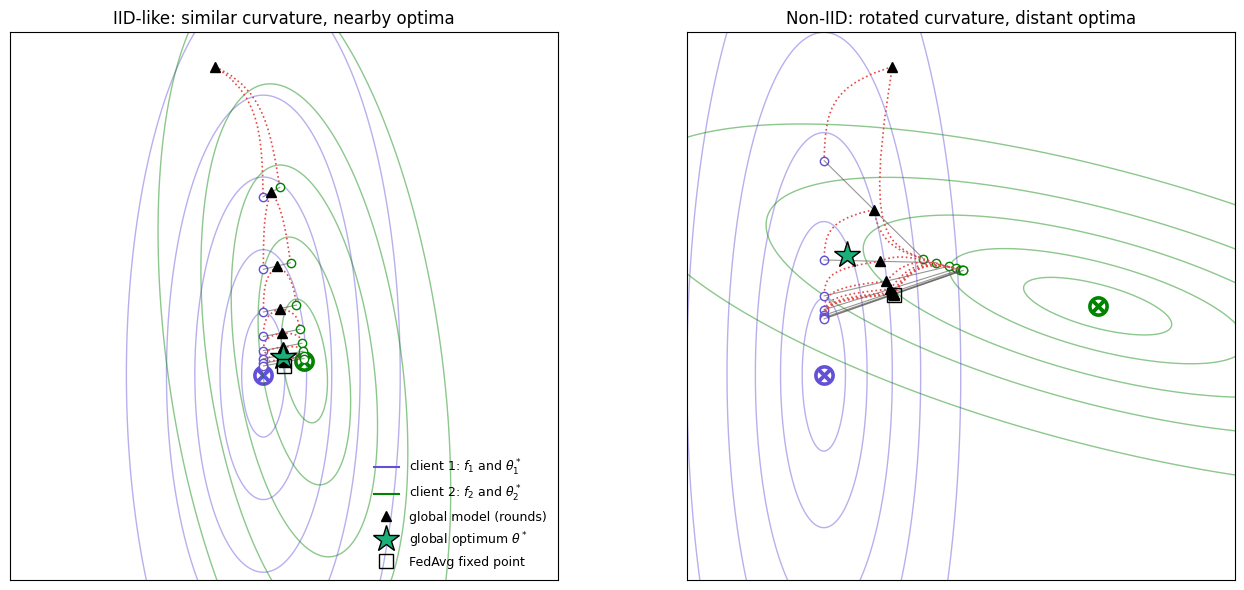

In [15]:
# Two toy settings with two clients each
toy_settings = {
    "IID-like: similar curvature, nearby optima": [
        make_client([1.0, 0.12], 0,  [-0.3, 0.0]),
        make_client([1.0, 0.12], 8,  [0.3, 0.2]),
    ],
    "Non-IID: rotated curvature, distant optima": [
        make_client([1.0, 0.08], 0,  [-2.0, 0.0]),
        make_client([1.0, 0.08], 75, [2.0, 1.0]),
    ],
}
p_toy, eta_toy, K_toy, theta0_toy, rounds_toy = [0.5, 0.5], 0.3, 15, [-1.0, 4.5], 8

client_colors = [COLORS["client_1"], COLORS["client_2"]]   # one color per client

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
grid = np.linspace(-5, 5, 300)  
G1, G2 = np.meshgrid(grid, grid) # each (300, 300)
pts = np.stack([G1.ravel(), G2.ravel()], axis=1) # flatten grids and sequentially stack : (90000, 2)

for ax, (title, clients) in zip(axes, toy_settings.items()):
    # Loss contours of each client
    for c, col in zip(clients, client_colors):
        d = pts - c["opt"] # subtract client optimum from each  
        # Einstein summation is used to plot the contour lines of a second-order Taylor approx. using the distance vectors from the client optimum and the corresponding Hessian
        # It estimates the quadratic form for each client : f_i = (1/2)*(d_i)^T@ H @(d_i)
        # Index breakdown for "ij,jk,ik->i":
        #   'ij' : d (N_points, 2) -> i = grid point index, j = coordinate index
        #   'jk' : H (2, 2)        -> j = row index, k = column index
        #   'ik' : d (N_points, 2) -> i = grid point index, k = coordinate index
        #   '->i': Sums over j and k, returning a 1D array of scalar loss values of shape (N_points,)
        # This is equivalent to np.sum((d @ c["H"]) * d, axis=1) - at this small dimension there is no advantage to einsum other than elegance of notation and trying a new approach
        f = 0.5 * np.einsum("ij,jk,ik->i", d, c["H"], d).reshape(G1.shape) # reshape 1D output to 2D grid
        ax.contour(G1, G2, f, levels=[0.05, 0.2, 0.5, 1, 2], colors=col, alpha=0.45, linewidths=1) 
        ax.plot(*c["opt"], marker="$\\otimes$", markersize=14, color=col) # mark client optimum with a circle with an x (border = client color)

    # FedAvg trajectory
    globals_, paths = toy_fedavg(clients, p_toy, eta_toy, K_toy, theta0_toy, rounds_toy) # run FedAvg simulation 
    # Iterate over the client trajectories logged over each communication round
    for r, round_paths in enumerate(paths):
        for path, col in zip(round_paths, client_colors):
            ax.plot(path[:, 0], path[:, 1], ":", color="#e34948", linewidth=1.2) # red dotted line to mark local step-by-step optimization trajectories
            ax.plot(*path[-1], "o", mfc="white", mec=col, markersize=6) # mark the endpoint achieved by each client at each round with hollow circles (border = client color)
            ax.plot([path[-1, 0], globals_[r + 1, 0]], [path[-1, 1], globals_[r + 1, 1]],
                    color=COLORS["centralized"], linewidth=0.8, alpha=0.6) # draw a line from the client's local endpoint to the next round's aggregated global model
    # Mark the server's global model parameter state across all rounds using black triangles
    ax.plot(globals_[:, 0], globals_[:, 1], "^", color="black", markersize=7, label="global model (rounds)")
    
    theta_star, theta_fedavg, plain_avg = toy_optima(clients, p_toy, eta_toy, K_toy) # run analytical computation of optimization endpoints
    ax.plot(*theta_star, "*", color=COLORS["accent"], markersize=20, mec="black", label="global optimum $\\theta^*$") # mark global optimum with a star
    ax.plot(*theta_fedavg, "s", mfc="none", mec="black", markersize=10, label="FedAvg fixed point") # mark the FedAvg fixed point with a hollow square (border = black )
    ax.set_title(title)
    ax.set_xlim(-4, 4); ax.set_ylim(-3, 5); ax.set_aspect("equal")
    ax.set_xticks([]); ax.set_yticks([])

# Legend: add one entry per client (the contours themselves have no label)
from matplotlib.lines import Line2D
handles, _ = axes[0].get_legend_handles_labels()
handles = [Line2D([], [], color=COLORS["client_1"], label="client 1: $f_1$ and $\\theta_1^*$"),
           Line2D([], [], color=COLORS["client_2"], label="client 2: $f_2$ and $\\theta_2^*$")] + handles
axes[0].legend(handles=handles, loc="lower right", frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

<b>Reading the figure</b>
- <u>IID-like panel:</u> the two ellipses have almost the same shape and nearly the same center. Curvature weighting changes almost nothing, so the FedAvg fixed point practically coincides with ★ and the global model walks straight to it.
- <u>Non-IID panel:</u> the green ellipses are rotated and shifted, so $H_1 \neq H_2$ and $\theta_1^* \neq \theta_2^*$. Each local run is pulled towards its own $\otimes$, the average lands between them, and the global model settles at the FedAvg fixed point, <b>away from ★</b>.

The closed form also lets us see the effect of $K$ directly: the distance between the FedAvg fixed point and $\theta^*$, as the number of local steps grows.
- Try changing K_toy from 15 to 25: the average on the non-IID lands even further away from the global optimum.
- Try changing K_toy from 15 to 3: the average on the non-IID lands very close to the global optimum.

The plot below further examines the difference between the FedAvg average and the true global optimum (the client drift) as the number of gradient steps increases in the two scenarios.

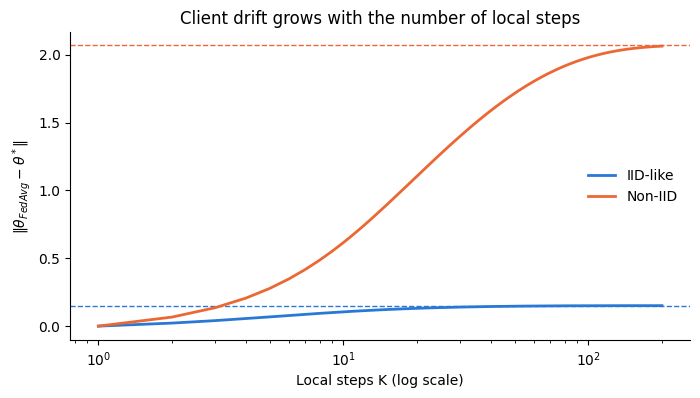

In [16]:
Ks = np.arange(1, 201) # range of local steps K = 1 to 200

fig, ax = plt.subplots(figsize=(8, 4))

# Iterate over IID and non-IID toy problems
# here the colors correspond to :  IID-like (blue) vs non-IID (orange) 
for (title, clients), col in zip(toy_settings.items(), [COLORS["iid"], COLORS["non_iid"]]):
    gaps = []
    for K in Ks:
        theta_star, theta_fedavg, plain_avg = toy_optima(clients, p_toy, eta_toy, K)
        gaps.append(np.linalg.norm(theta_fedavg - theta_star)) # calculate euclidean norm of the difference between FedAvg fixed point and global optimum 
    ax.plot(Ks, gaps, color=col, linewidth=2, label=title.split(":")[0])
    ax.axhline(np.linalg.norm(plain_avg - theta_star), color=col, linestyle="--", linewidth=1) # plot euclidean norm of plain average and global optimum (one-shot averaging K->infty limit)

ax.set_xscale("log")
ax.set_xlabel("Local steps K (log scale)")
ax.set_ylabel(r"$\|\theta_{FedAvg} - \theta^*\|$")
ax.set_title("Client drift grows with the number of local steps")
ax.legend(frameon=False)
ax.spines[["top", "right"]].set_visible(False)
plt.show()

At $K = 1$ the gap is zero in both settings. As $K$ grows, the non-IID gap rises towards the dashed line, which is the distance of the plain average of the local optima (the $K\rightarrow \infty$ limit). In the IID-like setting the gap stays small for every $K$.

<b>So is the problem that FedAvg has no second-order information?</b>

Partly, but the missing piece is really <b>global</b> information, not curvature at the client.
- A client running many gradient steps already "feels" its own curvature: its path bends along its ellipse and ends at $\theta_i^*$. Giving it its own $H_i$ would only get it to $\theta_i^*$ faster, which makes drift <u>worse</u>.
- FedAvg with $K = 1$ reaches the right answer using only gradients.

The failure has two parts:
1. <u>During local steps</u>, clients only see their own loss. After the first step, every step descends $f_i$ instead of $F$
2. <u>At aggregation</u>, the server averages points with weights $p_i$ only. The correct combination weights each local optimum by its curvature, which matters only when the $H_i$ differ

This splits the known remedies into two families ([Seo et al., 2025](https://arxiv.org/abs/2502.00182) group them as "adjusting the update path" and "modifying the loss landscape"). 
<br></br>

<u>Note on FedAvg: </u> the algorithm is first-order, but second-order thinking is what explains its failure mode: FedAvg fails on non-IID data because clients optimize their own objectives for many steps, and the server combines the results without accounting for how differently curved those objectives are.

The table below lists some of the most important <b>first- and second-order optimization approaches for the data heterogeneity problem in federated learning</b>:

| Method | Information used | Good for non-IID | Idea |
| ------ | ------ | ------ | ------ |
| [FedProx](https://arxiv.org/abs/1812.06127) | First-order | Yes|Adds $\frac{\mu}{2}\lVert\theta - \theta_t\rVert^2$ to each local problem, so local points cannot run all the way to $\theta_i^*$ (effectively a smaller $K$). $\mu$ controls how strong the penalty is: bigger means the local models cannot wander too far, smaller allows more exploration of the local search space.|
| [SCAFFOLD](https://arxiv.org/abs/1910.06378) | First-order | Yes |Control variates (error correction) adjust each client's gradient direction with an estimate of the global one, so local steps descend $F$ instead of $f_i$ |
| [FedNova](https://arxiv.org/abs/2007.07481) | First-order |Yes |Normalizes the scale of local updates by the number of local steps performed per client.  |
| [GIANT](https://arxiv.org/abs/1709.03528) | Second-order | No |Averages local Newton directions $H_i^{-1}\nabla F(\theta_t)$. Good only when the $H_i$ are similar, which is why it targets IID settings |
| [DANE](https://arxiv.org/abs/1312.7853) / [FedDANE](https://arxiv.org/abs/2001.01920) | First-order + global gradient to derive second-order information | No |Corrects each local problem with the global gradient, so the local solution approximates a Newton step without forming any Hessian. Works well under the assumption that the local data of each client mirrors the global data. |
| [Fisher-weighted merging](https://arxiv.org/abs/2111.09832) | Second-order (approx.) | Promising | Weights each model's parameters by a diagonal Fisher Information (curvature) estimate during averaging. This preserves critical specialized weights across heterogeneous or multi-task models.|

<b>Notes:</b>
- It is really interesting that the baseline intuition that involving second-order information would solve all our problems with regard to heterogeneity in data among clients is suggested to be false. In fact, the opposite seems to be the case, with traditional second-order optimization working better for IID data. However, Fisher-weighted merging, which approaches the problem from a statistical approximation perspective, considering the models as probability distributions with parameter importances based on curvature, shifts our attention from trying to align optimization paths to directly protecting critical parameters. By focusing on this, second-order information might be able to handle non-IID settings if it is utilized in conjunction with weight parameter importance instead of calculating step directions.

- A very popular current research objective in both industry and academia is <b>achieving good federated learning results in LLM fine-tuning with PEFT</b>, which is expectedly hindered by data heterogeneity among clients. This problem introduces a new challenge to client drift. In standard full parameter tuning, the client drift problem would be the same as here. However when it comes to PEFT fine-tuning, what is exchanged is information on the LoRA or QLoRA adapters, which are matrices of purposefully low rank in order to achieve meaningful dimensionality reduction that retains the most important information.
    - The adapters constrict the optimization to a highly constrained low subspace. In turn, this makes the impact of non-IID data amplified, plus the low-rank constraint does not allow for extra dimensions for models to compromise. Mathematically, matrix addition does not preserve rank boundaries. Averaging two distinct low-rank matrices from divergent client distributions often causes rank inflation (up to double the original rank for the case of 2 matrices only), which then requires either a larger rank or a lossy truncation (e.g. via SVD) upon aggregation. More generally, averaging the products $B_{i}A_{i}$ of $N$ clients can reach rank $N\cdot r$. Also, if $A$ and $B$ are averaged separately, the result $\bar{B}\bar{A}$ is not the average of $B_{i}A_{i}$. This structural breakdown due to non-linear aggregation and rank inflation is a central challenge in Federated PEFT, as formally detailed in the following sources: **FFA-LoRA** ([Sun et al., 2024](https://arxiv.org/abs/2403.12313)) and **FedEx-LoRA** ([Singhal et al., 2024](https://arxiv.org/abs/2410.09432)).

    -  Trajectory-based methods like most of the ones on the classical optimization table can struggle here. One possible reason (my hypothesis) is that the rigid directional adjustments they impose may corrupt the fragile information carried by these low-rank projections. On the other hand, leveraging Fisher-weighted merging shifts our focus from forcing trajectory alignment during training to protecting critical parameters during aggregation. It allows each adapter to be trained individually along its ideal local curve, using data-aware Fisher information to weight the global merge by parameter importance. This may help preserve specialized updates and localized knowledge. Note however that a Fisher-weighted average of $A$ and $B$ is still a separate average of the two factors, so on its own it does not fix the $\bar{B}\bar{A}$ mismatch above. Exact aggregation is addressed by a separate line of work (FFA-LoRA freezes $A$ and trains only $B$, FedEx-LoRA adds a residual correction to the frozen weights).
 
    - Publications and preprints for further reading on Fisher information & LoRA:
        -  [FR-LoRA](https://dl.acm.org/doi/10.1145/3746252.3761531)
        -  [Learning in the Fisher Subspace: A Guided Initialization for LoRA Fine-Tuning](https://arxiv.org/pdf/2605.01046) (centralized LoRA initialization: related, not federated)
        -  [Fisher-LoRA](https://openreview.net/pdf?id=alvkxFeQ4g)
    
*<b>Disclaimer:</b> this commentary is not exhaustive. It is to be amended if/when more meaningful relevant commentary comes to mind as I learn more. For now these are my personal initial brief notes on this subject. To be taken with a grain of salt.*

<mark><b>Caveat:</b> real neural-network losses are not quadratic, and the figure is a toy. The quadratic picture holds locally near a minimum, which is where convergence behavior is decided, so the intuition carries over.</mark>

<h2>The No-Attack Case: FedAvg on IID and Non-IID Clients</h2>

Before any client misbehaves, we need to know what "normal" looks like. In this section every client is honest, and we:
- define the model and the metrics
- build FedAvg from small pieces and walk through a single round
- compare FedAvg on IID and non-IID clients against a centralized baseline
- check whether the client drift predicted above shows up when we vary the number of local steps

These results are the reference point for everything that follows in the Byzantine sections.

<h3>The Model</h3>

A small CNN in the spirit of the sister notebook (see there for why CNNs and what each layer does). The input is larger ($80 \times 80$ instead of $32 \times 32$), so we use three Convolution $\rightarrow$ ReLU $\rightarrow$ Max Pool blocks to shrink the feature maps before the fully connected layers.

| Stage | Operation | Output shape | Comment |
|------|----------|---------|---------|
| Input | 3 × 80 × 80 image | 3 × 80 × 80 | RGB chip |
| 1 | Conv (16 filters) → ReLU → Max Pool | 16 × 40 × 40 | Local patterns (edges, bright spots) |
| 2 | Conv (32 filters) → ReLU → Max Pool | 32 × 20 × 20 | Combine lower-level features |
| 3 | Conv (64 filters) → ReLU → Max Pool | 64 × 10 × 10 | Ship-sized structures |
| 4 | Flatten | 6400 | Feature maps to vector |
| 5 | Fully Connected → ReLU | 64 | Classification |
| Output | Fully Connected | 1 logit | Ship score |

<u>Notes:</u>
- <b>No BatchNorm.</b> BatchNorm layers keep running means and variances as <i>buffers</i> next to the parameters.
    - Note: Averaging those statistics across clients with different data distributions is problematic and an active topic of its own ([Hsieh et al., 2020](https://arxiv.org/abs/1910.00189); [FedBN](https://arxiv.org/abs/2102.07623)).
    - Without BatchNorm, the model's state is exactly its parameters, which keeps aggregation clean.
- <b>One output logit</b> instead of two, since the task is binary. The probability of "ship" is $\sigma(\text{logit})$, and predicting "ship" when $\sigma(\text{logit}) > 0.5$ is the same as predicting it when $\text{logit} > 0$.

In [17]:
class ShipCNN(nn.Module):
    """
        A small CNN for binary ship / no-ship classification of 80x80 RGB chips
    """

    def __init__(self):
        super().__init__()

        # -------------------------
        # Convolutional blocks (padding=1 keeps the spatial size, pooling halves it)
        self.conv1 = nn.Conv2d(3, 16, kernel_size=3, padding=1)    # -> (B, 16, 80, 80)
        self.conv2 = nn.Conv2d(16, 32, kernel_size=3, padding=1)   # -> (B, 32, 40, 40)
        self.conv3 = nn.Conv2d(32, 64, kernel_size=3, padding=1)   # -> (B, 64, 20, 20)
        # -------------------------

        # -------------------------
        # Fully connected layers
        # After three rounds of pooling: 80 -> 40 -> 20 -> 10
        # Feature map size: 64 channels x 10 x 10 = 6400 features
        self.fc1 = nn.Linear(64 * 10 * 10, 64)
        self.fc2 = nn.Linear(64, 1)   # a single logit: the ship score
        # -------------------------

    def forward(self, x):
        """
        x shape: (batch_size, 3, 80, 80)
        """
        # (1)-(3) Convolution -> ReLU -> Max Pool, three times
        x = F.max_pool2d(F.relu(self.conv1(x)), kernel_size=2)   # 80 -> 40
        x = F.max_pool2d(F.relu(self.conv2(x)), kernel_size=2)   # 40 -> 20
        x = F.max_pool2d(F.relu(self.conv3(x)), kernel_size=2)   # 20 -> 10

        # (4) Flatten -> (B, C*H*W); flatten(1) keeps the batch dimension
        x = x.flatten(1)

        # (5) Fully connected layer
        x = F.relu(self.fc1(x))

        # Output logit (no sigmoid here: the loss applies it internally)
        return self.fc2(x).squeeze(1)   # (B, 1) -> (B,)

In [18]:
model = ShipCNN().to(device)
num_params = sum(p.numel() for p in model.parameters())
print(f"Trainable parameters: {num_params:,}")

Trainable parameters: 433,313


<b>Loss function:</b> `F.binary_cross_entropy_with_logits` combines the sigmoid and the binary cross-entropy in one function. This is numerically more stable than applying `sigmoid` and then `BCELoss` separately, because very large or very small logits would otherwise saturate to exactly 0 or 1 and produce `log(0)`.

<h3>Evaluation Metrics</h3>

Treating "ship" as the positive class, each test prediction falls into one of four groups:

| | Predicted ship | Predicted no-ship |
| --- | --- | --- |
| <b>Actual ship</b> | True Positive (TP) | False Negative (FN): a missed ship |
| <b>Actual no-ship</b> | False Positive (FP): a false alarm | True Negative (TN) |

- <b>Accuracy</b> $= \frac{TP + TN}{\text{all}}$: share of correct predictions. Misleading here, since "always no-ship" already scores 75%
- <b>Recall</b> (ship) $= \frac{TP}{TP + FN}$: share of the actual ships that were found. <u>Note for the Byzantine case that will be examined further: This is the metric a "make ships disappear" attack targets</u>
- <b>Precision</b> (ship) $= \frac{TP}{TP + FP}$: share of "ship" alarms that really are ships
- <b>F1</b> $= 2 \cdot \frac{\text{precision} \cdot \text{recall}}{\text{precision} + \text{recall}}$: a single number that is only high when both are high

Chosen for reporting: <b>accuracy</b> and <b>ship recall</b> as the main pair, and F1 as a summary.

In [19]:
@torch.no_grad()   # decorator version of "with torch.no_grad():" for the whole function
def evaluate(model, X, y, batch_size=512):
    model.eval()
    logits = torch.cat([model(X[i:i + batch_size]) for i in range(0, len(X), batch_size)])   # batched forward pass keeps GPU memory bounded
    loss = F.binary_cross_entropy_with_logits(logits, y).item()

    pred = (logits > 0).float()   # logit > 0  <=>  sigmoid(logit) > 0.5
    tp = ((pred == 1) & (y == 1)).sum().item()
    fp = ((pred == 1) & (y == 0)).sum().item()
    fn = ((pred == 0) & (y == 1)).sum().item()

    precision = tp / (tp + fp) if tp + fp > 0 else 0.0
    recall = tp / (tp + fn) if tp + fn > 0 else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0.0
    accuracy = (pred == y).float().mean().item()
    return {"loss": loss, "accuracy": accuracy, "precision": precision, "recall": recall, "f1": f1}


# An untrained model -  sanity check
evaluate(model, X_test, y_test)

{'loss': 0.7191298007965088,
 'accuracy': 0.25,
 'precision': 0.25,
 'recall': 1.0,
 'f1': 0.4}

<h3>Federated Building Blocks</h3>

FedAvg needs three pieces:
1. a way to read and write a model's parameters as <b>one flat vector</b>
2. <b>local training</b> on a client
3. <b>server aggregation</b>

<b>1. Models as vectors</b>

`parameters_to_vector` concatenates every parameter tensor into a single vector $\theta \in \mathbb{R}^d$, and `vector_to_parameters` writes a vector back into the model.
- aggregation becomes simple vector arithmetic over an $(N, d)$ matrix of client updates
- the Byzantine defenses that will be explored later in the notebook work on exactly these vectors (e.g. Krum compares distances between them)

In [20]:
def get_vector(model):
    # detach: no gradient history; clone: an independent copy, not a view of the parameters
    return parameters_to_vector(model.parameters()).detach().clone()


def set_vector(model, vec):
    # CAUTION: vector_to_parameters makes the parameters *views* into vec. 
    # clone: necessary so that training the model does not silently modify vec in place (e.g. the global model).
    vector_to_parameters(vec.clone(), model.parameters())

<b>2. Local training</b>

The client starts from the global model and runs SGD on its own data for $E$ local epochs, which is $K_i = E \cdot \lceil n_i / B \rceil$ steps. The training loop has a simple structure of forward pass, loss, backward pass and update.

<u>Notes:</u>
- a <b>fresh optimizer</b> is created every round, so the momentum buffer starts from zero each time. This is the usual choice in FL simulations: the momentum state is computed on the client's own data and would otherwise carry stale information between rounds
- a single model object is <b>reused</b> for all clients: since clients are simulated one after another, we just overwrite its parameters with the global vector before each local run. This saves memory compared to one model per client
- batches come from `torch.randperm`, a random permutation of the local indices, generated directly on the GPU

In [21]:
def local_train(model, global_vec, X_i, y_i, cfg):
    """Runs E local epochs of SGD starting from the global model. Returns the local model as a vector."""
    
    set_vector(model, global_vec) # vector to params
    model.train()
    optimizer = torch.optim.SGD(model.parameters(), lr=cfg.lr, momentum=cfg.momentum)   # fresh optimizer every round: momentum restarts from zero

    n_i = len(X_i)
    running_loss, steps = torch.tensor(0.0, device=X_i.device), 0
    for epoch in range(cfg.local_epochs):
        perm = torch.randperm(n_i, device=X_i.device)   # shuffle the local data every epoch and get a rand permutation 
        for start in range(0, n_i, cfg.batch_size):
            batch = perm[start:start + cfg.batch_size]  # mini-batch

            optimizer.zero_grad()                       # clear gradients
            loss = F.binary_cross_entropy_with_logits(model(X_i[batch]), y_i[batch]) # calculate loss
            loss.backward()                             # get gradients w.r.t. the parameters
            optimizer.step()                            # update

            running_loss += loss.detach()               # stays on the GPU, no sync per step
            steps += 1

    return get_vector(model), running_loss.item() / steps, steps   # (local weights, mean local loss, K_i)

<b>3. Server aggregation</b>

FedAvg in update form, $\sum_i p_i\,\Delta_i$ with $p_i = n_i / n$.

In [22]:
def fedavg_aggregate(updates, client_sizes):
    """Weighted average of the client updates (a list of N vectors of size d)."""
    stacked = torch.stack(updates)                                   # (N, d)
    p = torch.tensor(client_sizes, dtype=stacked.dtype, device=stacked.device)
    p = p / p.sum()                                                  # p_i = n_i / n
    return (p[:, None] * stacked).sum(dim=0)                         # (N, 1) * (N, d) -> sum -> (d,)

<b>PyTorch note:</b> `p[:, None]` adds a dimension, turning shape $(N,)$ into $(N, 1)$. Broadcasting then multiplies every row $i$ of the $(N, d)$ matrix by its weight $p_i$.

<h3>Walking Through One Round</h3>

Before wrapping everything into a function, a single FedAvg round step by step, on the IID partition from before.

In [23]:
### ONE FEDAVG ROUND, STEP BY STEP ###

set_seed(0)
model = ShipCNN().to(device)
global_vec = get_vector(model)       # theta_t: the global model the server holds

# Each client's data, indexed once (also creates a copy on the GPU)
clients = [(X_train[torch.as_tensor(idx, device=device)],
            y_train[torch.as_tensor(idx, device=device)]) for idx in iid_parts]
client_sizes = [len(idx) for idx in iid_parts]

print("Before the round:", {k: round(v, 3) for k, v in evaluate(model, X_test, y_test).items()})

# (1) + (2) Server broadcasts theta_t, every client trains locally and returns its update
updates = []
for i, (X_i, y_i) in enumerate(clients):
    local_vec, local_loss, steps = local_train(model, global_vec, X_i, y_i, cfg)
    delta = local_vec - global_vec                       # Delta_i = theta_{t,i} - theta_t
    updates.append(delta)
    print(f"client {i}: n_i = {client_sizes[i]:3d} | K_i = {steps:3d} steps | "
          f"local loss = {local_loss:.3f} | ||Delta_i|| = {delta.norm():.3f}")

# (3) Server aggregates: theta_{t+1} = theta_t + sum_i p_i Delta_i
global_vec = global_vec + fedavg_aggregate(updates, client_sizes)
set_vector(model, global_vec)

print("After the round: ", {k: round(v, 3) for k, v in evaluate(model, X_test, y_test).items()})

Before the round: {'loss': 0.675, 'accuracy': 0.75, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0}
client 0: n_i = 320 | K_i =  20 steps | local loss = 0.609 | ||Delta_i|| = 0.437
client 1: n_i = 320 | K_i =  20 steps | local loss = 0.606 | ||Delta_i|| = 0.429
client 2: n_i = 320 | K_i =  20 steps | local loss = 0.626 | ||Delta_i|| = 0.401
client 3: n_i = 320 | K_i =  20 steps | local loss = 0.630 | ||Delta_i|| = 0.390
client 4: n_i = 320 | K_i =  20 steps | local loss = 0.600 | ||Delta_i|| = 0.442
client 5: n_i = 320 | K_i =  20 steps | local loss = 0.596 | ||Delta_i|| = 0.467
client 6: n_i = 320 | K_i =  20 steps | local loss = 0.640 | ||Delta_i|| = 0.327
client 7: n_i = 320 | K_i =  20 steps | local loss = 0.612 | ||Delta_i|| = 0.405
client 8: n_i = 320 | K_i =  20 steps | local loss = 0.614 | ||Delta_i|| = 0.418
client 9: n_i = 320 | K_i =  20 steps | local loss = 0.605 | ||Delta_i|| = 0.444
After the round:  {'loss': 0.564, 'accuracy': 0.75, 'precision': 0.0, 'recall': 0.0, 'f1': 0.0

Things to notice:
- every client starts from the same $\theta_t$, but each returns a different update
- in the IID case the update norms $\lVert\Delta_i\rVert$ are similar across clients, because every client sees the same kind of data
- after a single round the model may still predict mostly "no-ship" (accuracy near 75%, low recall), which is the imbalance trap from earlier

<h3>The Full Training Loop</h3>

Repeating the round $T$ times gives the full FedAvg run. After every round, the global model is evaluated on the central test set.

In [24]:
def run_fedavg(partition, cfg, seed):
    """Runs FedAvg for cfg.rounds rounds. Returns the test metrics after every round."""
    set_seed(seed)
    model = ShipCNN().to(device)   # global model, also reused as the local "worker"
    global_vec = get_vector(model)

    clients = [(X_train[torch.as_tensor(idx, device=device)],   # index each client's data once, not every round
                y_train[torch.as_tensor(idx, device=device)]) for idx in partition]
    client_sizes = [len(idx) for idx in partition]

    history = []
    for t in range(cfg.rounds):
        updates = [local_train(model, global_vec, X_i, y_i, cfg)[0] - global_vec   # [0]: keep only the local vector -> Delta_i
                   for X_i, y_i in clients]
        global_vec = global_vec + fedavg_aggregate(updates, client_sizes)

        set_vector(model, global_vec)   # load the new global model for evaluation
        history.append({"round": t + 1, **evaluate(model, X_test, y_test)})
    return history

<b>Centralized baseline.</b> The same model trained on the pooled training set, as the upper bound FL is aiming for.
- to compare fairly, one "round" of centralized training is $E$ epochs over the whole training set, so both settings process the same number of samples per round
- unlike the clients, the centralized optimizer keeps its momentum across rounds, because there is nothing to reset

In [25]:
def run_centralized(cfg, seed):
    """Trains on the pooled data. Evaluates every E epochs, to line up with the FL rounds."""
    set_seed(seed)
    model = ShipCNN().to(device)
    optimizer = torch.optim.SGD(model.parameters(), lr=cfg.lr, momentum=cfg.momentum)   # one optimizer for the whole run: momentum persists, unlike in FL

    history = []
    for t in range(cfg.rounds):
        model.train()   # evaluate() switches to eval mode, so switch back every round
        for epoch in range(cfg.local_epochs):
            perm = torch.randperm(len(X_train), device=device)
            for start in range(0, len(X_train), cfg.batch_size):
                batch = perm[start:start + cfg.batch_size]
                optimizer.zero_grad()
                loss = F.binary_cross_entropy_with_logits(model(X_train[batch]), y_train[batch])
                loss.backward()
                optimizer.step()
        history.append({"round": t + 1, **evaluate(model, X_test, y_test)})
    return history

<b>Caching results.</b> As with the saved `.pt` checkpoints in the sister notebook, every experiment is saved to `./results` together with the config that produced it. Re-running a cell loads the saved results instead of retraining, unless `cfg.rerun = True`.

In [26]:
def run_or_load(name, experiment_fn, cfg):
    path = Path(cfg.results_dir) / f"{name}.json"
    if path.exists() and not cfg.rerun:   # reuse cached results unless a rerun is forced
        print(f"Loaded cached results from {path}")
        return json.loads(path.read_text())["results"]

    start = time.time()
    results = experiment_fn(cfg)
    path.parent.mkdir(parents=True, exist_ok=True)
    path.write_text(json.dumps({"config": asdict(cfg), "results": results}))   # config saved next to the results for reproducibility
    print(f"Finished in {time.time() - start:.0f}s, saved to {path}")
    return results

Two plotting helpers: learning curves (mean $\pm$ std over seeds) and a final-round summary table.

In [27]:
def stack_metric(runs, metric):
    """List of histories (one per seed) -> array of shape (seeds, rounds)."""
    return np.array([[h[metric] for h in run] for run in runs])


def plot_curves(results, colors, metrics=("accuracy", "recall"), title=None):
    fig, axes = plt.subplots(1, len(metrics), figsize=(6 * len(metrics), 4))
    for ax, metric in zip(axes, metrics):
        for name, runs in results.items():
            vals = stack_metric(runs, metric)
            mean, std = vals.mean(0), vals.std(0)   # across seeds, per round
            rounds = np.arange(1, vals.shape[1] + 1)
            style = "--" if name == "Centralized" else "-"
            ax.plot(rounds, mean, style, color=colors[name], linewidth=2, label=name)
            ax.fill_between(rounds, mean - std, mean + std, color=colors[name], alpha=0.15)
        if metric == "accuracy":
            ax.axhline(0.75, color="black", linestyle=":", linewidth=1)   # majority-class baseline (3:1 imbalance)
            ax.text(1, 0.755, 'always "no-ship"', fontsize=9, va="bottom")
        ax.set_xlabel("Communication round")
        ax.set_ylabel(metric if metric != "recall" else "ship recall")
        ax.set_ylim(0, 1.02)
        ax.spines[["top", "right"]].set_visible(False)
    axes[0].legend(frameon=False, loc="lower right")
    if title:
        fig.suptitle(title)
    plt.tight_layout()
    plt.show()


def summary_table(results, metrics=("accuracy", "recall", "precision", "f1")):
    print(f"{'':<22}" + "".join(f"{m:>19}" for m in metrics))
    for name, runs in results.items():
        row = ""
        for m in metrics:
            final = stack_metric(runs, m)[:, -1]   # last round of every seed
            row += f"{final.mean():>11.3f} ± {final.std():.3f}"
        print(f"{name:<22}" + row)

<h3>Experiment 1: IID vs Non-IID</h3>

<b>Questions:</b>
1. <b>Does FedAvg on IID clients match centralized training?</b> In the IID case every client is a small copy of the full dataset, so we expect FedAvg to come close to the centralized baseline.
2. <b>How much does non-IID data cost?</b> From the optimization perspective we expect slower and noisier convergence, and possibly a lower final score.
3. <b>Does non-IID data hurt ship recall more than accuracy?</b> Most ships are concentrated on a few clients, so the ship class may be the one that suffers.

<b>Setup</b>
- 10 clients, 30 rounds, 2 local epochs, Dirichlet $\alpha = 0.5$
- 3 seeds. The seed controls both the model initialization and the partition, so the spread across seeds also includes the effect of <u>which</u> non-IID split was drawn
- for each seed, the IID and non-IID runs start from the same initial model

In [28]:
def experiment_iid_vs_non_iid(cfg):
    results = {"Centralized": [], "FedAvg (IID)": [], "FedAvg (non-IID)": []}
    for seed in cfg.seeds:
        rng = np.random.default_rng(seed)   # one rng per seed -> reproducible partitions
        iid_parts = iid_partition(len(y_train_np), cfg.num_clients, rng)
        non_iid_parts = dirichlet_partition(y_train_np, cfg.num_clients, cfg.dirichlet_alpha,
                                            rng, cfg.min_client_size)

        results["Centralized"].append(run_centralized(cfg, seed))
        results["FedAvg (IID)"].append(run_fedavg(iid_parts, cfg, seed))
        results["FedAvg (non-IID)"].append(run_fedavg(non_iid_parts, cfg, seed))
        print(f"seed {seed} done")
    return results


results_exp1 = run_or_load("exp1_iid_vs_non_iid", experiment_iid_vs_non_iid, cfg)

Loaded cached results from results/exp1_iid_vs_non_iid.json


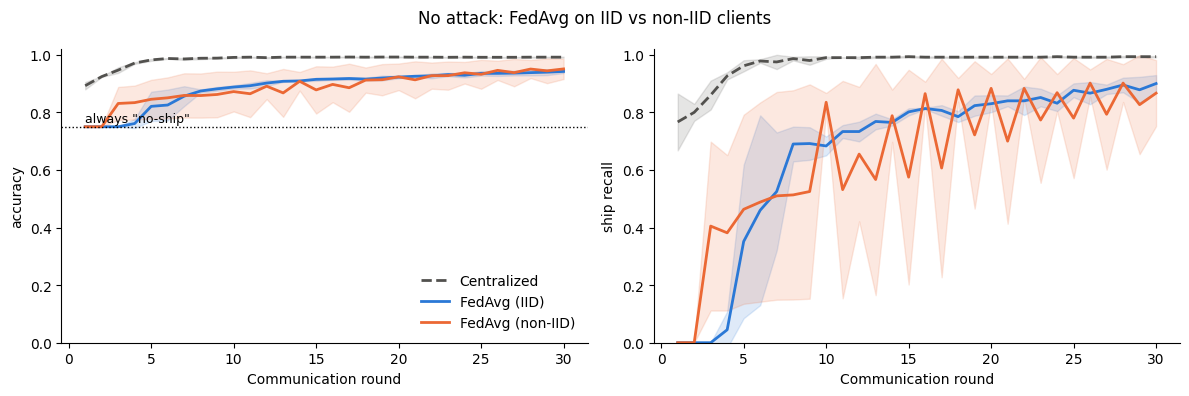

                                 accuracy             recall          precision                 f1
Centralized                 0.992 ± 0.002      0.993 ± 0.002      0.974 ± 0.005      0.984 ± 0.003
FedAvg (IID)                0.942 ± 0.006      0.900 ± 0.029      0.873 ± 0.006      0.886 ± 0.013
FedAvg (non-IID)            0.951 ± 0.035      0.867 ± 0.115      0.928 ± 0.037      0.894 ± 0.080


In [29]:
colors_exp1 = {"Centralized": COLORS["centralized"],
               "FedAvg (IID)": COLORS["iid"],
               "FedAvg (non-IID)": COLORS["non_iid"]}

plot_curves(results_exp1, colors_exp1, title="No attack: FedAvg on IID vs non-IID clients")
summary_table(results_exp1)

Things to look for:
- how close the IID curve gets to the centralized one, and after how many rounds
- whether the non-IID curves are lower, slower or more jagged, and how wide the band across seeds is
- whether the gap between IID and non-IID is larger for ship recall than for accuracy
- whether any run stays on the "always no-ship" line for the first rounds

<b>Brief results comments for initial settings:</b>
- Centralized case: high accuracy and recall within fewer than 10 rounds, with high robustness across seeded experiments
- FedAvg (IID) case: Achieves accuracy close but still lower than the Centralized case (also quite robust) as rounds go to 30 which is the experiment max. Recall on the other hand rises more slowly, with some deviation among seeded results in the early rounds, and reaches a high value that is still below the Centralized case.
- FedAvg (non-IID) case: Achieves accuracy close but still lower than the Centralized case (less robust, with more fluctuation along the way) as rounds go to 30 which is the experiment max. Interestingly, it leaves the "always no-ship" line earlier than the IID case, possibly because the ship-heavy clients send strong "ship" updates that are not diluted. Recall is highly unstable with big deviations among seeded results. However, as rounds approach 30 the fluctuations become smaller, although they are still present at round 30. 

Overall, when looking at the final scores and standard deviations, final metrics remain high enough for models to be functional. Non-IID costs more in stability, with the oscillations being consistent with the clients pulling the model back and forth due to their different data distributions. The oscillation shows mostly in recall rather than accuracy, i.e. mostly in how the (minority) ship class is treated. Also, since curves are increasing for both IID and non-IID cases, this suggests that if the communication round budget increases we will observe higher metric values and more stable behavior. 

Accuracy in all cases reaches above the "always no-ship" result.

<b>Back to the questions:</b>
1. Not yet: after 30 rounds IID FedAvg is still ~0.05 below Centralized in accuracy and ~0.09 in recall, which looks like a round-budget limit rather than a hard ceiling.
2. The cost of non-IID data shows mostly in stability (oscillations, wide spread across seeds), not in the final score.
3. Not supported with 3 seeds: non-IID recall is 0.867 ± 0.115 vs 0.900 ± 0.029 for IID, a difference smaller than the non-IID spread across seeds.

<h3>Experiment 2: Local Steps and Client Drift</h3>

<b>Does the client drift predicted by the toy example show up in a real network?</b>

The theory says the gap between where FedAvg ends up and the true optimum grows with the number of local steps $K$, but only when the clients are non-IID. We test this by varying the local epochs $E \in \{1, 2, 5\}$ for both partitions, with everything else fixed.

<b>Note:</b> with the number of rounds fixed, more local epochs also means more total computation, which on its own tends to <u>improve</u> the results. So the absolute scores are not the point. What matters is the <b>gap between IID and non-IID</b>: if drift is real, that gap should widen as $E$ grows.

In [30]:
LOCAL_EPOCHS_GRID = (1, 2, 5)

def experiment_local_epochs(cfg):
    results = {}
    for E in LOCAL_EPOCHS_GRID:
        cfg_E = replace(cfg, local_epochs=E)    # copy of cfg with only E changed
        results[str(E)] = {"FedAvg (IID)": [], "FedAvg (non-IID)": []}   # str keys: JSON object keys are always strings
        for seed in cfg.seeds:
            rng = np.random.default_rng(seed)   # same partitions as in Experiment 1
            iid_parts = iid_partition(len(y_train_np), cfg.num_clients, rng)
            non_iid_parts = dirichlet_partition(y_train_np, cfg.num_clients, cfg.dirichlet_alpha,
                                                rng, cfg.min_client_size)
            results[str(E)]["FedAvg (IID)"].append(run_fedavg(iid_parts, cfg_E, seed))
            results[str(E)]["FedAvg (non-IID)"].append(run_fedavg(non_iid_parts, cfg_E, seed))
        print(f"E = {E} done")
    return results


results_exp2 = run_or_load("exp2_local_epochs", experiment_local_epochs, cfg)

Loaded cached results from results/exp2_local_epochs.json


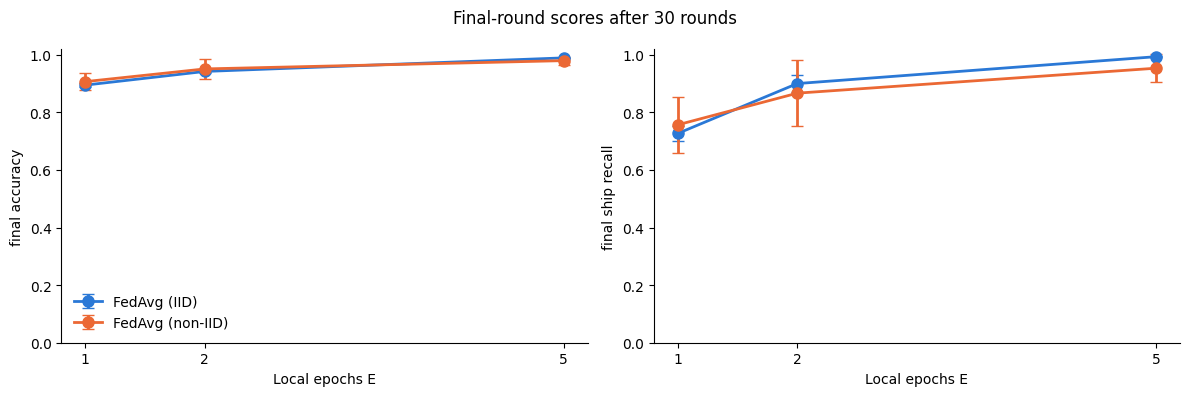


E = 1
                                 accuracy             recall          precision                 f1
FedAvg (IID)                0.895 ± 0.008      0.727 ± 0.027      0.832 ± 0.029      0.775 ± 0.016
FedAvg (non-IID)            0.907 ± 0.029      0.757 ± 0.097      0.851 ± 0.038      0.799 ± 0.071

E = 2
                                 accuracy             recall          precision                 f1
FedAvg (IID)                0.942 ± 0.006      0.900 ± 0.029      0.873 ± 0.006      0.886 ± 0.013
FedAvg (non-IID)            0.951 ± 0.035      0.867 ± 0.115      0.928 ± 0.037      0.894 ± 0.080

E = 5
                                 accuracy             recall          precision                 f1
FedAvg (IID)                0.989 ± 0.001      0.993 ± 0.002      0.964 ± 0.002      0.979 ± 0.001
FedAvg (non-IID)            0.980 ± 0.014      0.953 ± 0.048      0.964 ± 0.012      0.958 ± 0.030


In [31]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, metric in zip(axes, ["accuracy", "recall"]):
    for name, col in [("FedAvg (IID)", COLORS["iid"]), ("FedAvg (non-IID)", COLORS["non_iid"])]:
        finals = [stack_metric(results_exp2[str(E)][name], metric)[:, -1] for E in LOCAL_EPOCHS_GRID]   # final-round score of every seed, for each E
        means, stds = [f.mean() for f in finals], [f.std() for f in finals]
        ax.errorbar(LOCAL_EPOCHS_GRID, means, yerr=stds, color=col, marker="o", markersize=8,
                    linewidth=2, capsize=4, label=name)
    ax.set_xticks(LOCAL_EPOCHS_GRID)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("Local epochs E")
    ax.set_ylabel(f"final {metric if metric != 'recall' else 'ship recall'}")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(frameon=False)
fig.suptitle(f"Final-round scores after {cfg.rounds} rounds")
plt.tight_layout()
plt.show()

for E in LOCAL_EPOCHS_GRID:
    print(f"\nE = {E}")
    summary_table(results_exp2[str(E)])

Things to look for:
- whether the IID-non-IID gap widens with $E$, as the client-drift argument predicts
- whether $E = 5$ helps the IID case (more computation per round) while helping the non-IID case less, or even hurting it
- how the spread across seeds changes with $E$

<b>Brief results comments for initial settings:</b>
- Accuracy: no significant gap observed, however different seeds do produce some deviations in the non-IID case for any number of epochs E.
- Recall: there is a very small gap that starts to appear from $E = 2$ onward (~0.03-0.04 in favor of IID). The non-IID case achieves slightly lower recall values on average, within the variance across seeds (at $E = 1$ it is even slightly higher), however both have an increasing direction.

<b>Next step:</b> rerun with a lower $\alpha$ (e.g. 0.1). A more skewed split should make the client drift, and therefore the gap, more pronounced. Other possible reasons for the small gap are the limited number of rounds and the step size.

<h2>Next: The Byzantine Threat Model</h2>

So far every client has been honest. The next sections ask: <b>what happens when some of them are not?</b>
- what "Byzantine" means, and what the attacker knows and controls
- a realistic attack: compromised stations relabeling their ships as open ocean
- Krum, a defense that assumes a known fraction of the clients is faulty, and what it costs when they are all honest
- why non-IID data makes the problem fundamentally harder: an attacker and an honest but unusual client can look alike

<h2>Resources</h2>

Data:
- <a href="https://www.kaggle.com/datasets/rhammell/ships-in-satellite-imagery">Ships in Satellite Imagery (Kaggle, rhammell)</a>, CC BY-SA 4.0, imagery by <a href="https://www.planet.com/">Planet</a>

Federated Learning:
- <a href="https://arxiv.org/abs/1602.05629">McMahan et al. (2017), Communication-Efficient Learning of Deep Networks from Decentralized Data</a> (FedAvg)
- <a href="https://arxiv.org/abs/1912.04977">Kairouz et al. (2021), Advances and Open Problems in Federated Learning</a>
- <a href="https://arxiv.org/abs/1908.07873">Li et al. (2020), Federated Learning: Challenges, Methods, and Future Directions</a>

Non-IID data and client drift:
- <a href="https://arxiv.org/abs/2502.00182">Seo, Catak, Rong (2025), Understanding Federated Learning from IID to Non-IID dataset: An Experimental Study</a>
- <a href="https://arxiv.org/abs/1806.00582">Zhao et al. (2018), Federated Learning with Non-IID Data</a>
- <a href="https://arxiv.org/abs/1909.06335">Hsu, Qi, Brown (2019), Measuring the Effects of Non-Identical Data Distribution for Federated Visual Classification</a> (Dirichlet partitioning)
- <a href="https://arxiv.org/abs/1907.02189">Li et al. (2020), On the Convergence of FedAvg on Non-IID Data</a>
- <a href="https://arxiv.org/abs/1910.00189">Hsieh et al. (2020), The Non-IID Data Quagmire of Decentralized Machine Learning</a>
- <a href="https://arxiv.org/abs/2102.07623">Li et al. (2021), FedBN: Federated Learning on Non-IID Features via Local Batch Normalization</a>

Byzantine robustness:
- <a href="https://doi.org/10.1145/357172.357176">Lamport, Shostak, Pease (1982), The Byzantine Generals Problem</a>
- <a href="https://arxiv.org/abs/1703.02757">Blanchard et al. (2017), Machine Learning with Adversaries: Byzantine Tolerant Gradient Descent</a> (Krum)

Drift corrections: first and second-order methods:
- <a href="https://arxiv.org/abs/1812.06127">Li et al. (2020), Federated Optimization in Heterogeneous Networks</a> (FedProx)
- <a href="https://arxiv.org/abs/1910.06378">Karimireddy et al. (2020), SCAFFOLD: Stochastic Controlled Averaging for Federated Learning</a>
- <a href="https://arxiv.org/abs/2007.07481">Wang et al. (2020), Tackling the Objective Inconsistency Problem in Heterogeneous Federated Optimization</a> (FedNova)
- <a href="https://arxiv.org/abs/1312.7853">Shamir, Srebro, Zhang (2014), Communication-Efficient Distributed Optimization using an Approximate Newton-type Method</a> (DANE)
- <a href="https://arxiv.org/abs/1709.03528">Wang et al. (2018), GIANT: Globally Improved Approximate Newton Method for Distributed Optimization</a>
- <a href="https://arxiv.org/abs/2001.01920">Li et al. (2019), FedDANE: A Federated Newton-Type Method</a>
- <a href="https://arxiv.org/abs/2111.09832">Matena, Raffel (2022), Merging Models with Fisher-Weighted Averaging</a>

PyTorch:
- <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.parameters_to_vector.html">torch.nn.utils.parameters_to_vector</a> and <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.utils.vector_to_parameters.html">vector_to_parameters</a>
- <a href="https://docs.pytorch.org/docs/stable/generated/torch.nn.BCEWithLogitsLoss.html">BCEWithLogitsLoss</a>
- <a href="https://docs.pytorch.org/docs/stable/notes/randomness.html">Reproducibility</a>